In [ ]:
import pandas as pd
from google.colab import files

uploaded = files.upload()

Saving EastWestAirlines (1).xlsx to EastWestAirlines (1).xlsx


In [ ]:
df = pd.read_excel("EastWestAirlines (1).xlsx", sheet_name="data")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3999 entries, 0 to 3998
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   ID#                3999 non-null   int64
 1   Balance            3999 non-null   int64
 2   Qual_miles         3999 non-null   int64
 3   cc1_miles          3999 non-null   int64
 4   cc2_miles          3999 non-null   int64
 5   cc3_miles          3999 non-null   int64
 6   Bonus_miles        3999 non-null   int64
 7   Bonus_trans        3999 non-null   int64
 8   Flight_miles_12mo  3999 non-null   int64
 9   Flight_trans_12    3999 non-null   int64
 10  Days_since_enroll  3999 non-null   int64
 11  Award?             3999 non-null   int64
dtypes: int64(12)
memory usage: 375.0 KB


In [ ]:
print(df.isna().sum())

ID#                  0
Balance              0
Qual_miles           0
cc1_miles            0
cc2_miles            0
cc3_miles            0
Bonus_miles          0
Bonus_trans          0
Flight_miles_12mo    0
Flight_trans_12      0
Days_since_enroll    0
Award?               0
dtype: int64


In [ ]:
print("Duplicate full rows:", df.duplicated().sum())
print("Repeated customer IDs:", df["ID#"].duplicated().sum())

Duplicate full rows: 0
Repeated customer IDs: 0


In [ ]:
X = df.drop(columns=["ID#"]).copy()

print("Original dataset:", df.shape)
print("Clustering features:", X.shape)
display(X.head())

Original dataset: (3999, 12)
Clustering features: (3999, 11)


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,28143,0,1,1,1,174,1,0,0,7000,0
1,19244,0,1,1,1,215,2,0,0,6968,0
2,41354,0,1,1,1,4123,4,0,0,7034,0
3,14776,0,1,1,1,500,1,0,0,6952,0
4,97752,0,4,1,1,43300,26,2077,4,6935,1


In [ ]:
display(X.describe().round(2))

,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
count,3999.00,3999.00,3999.00,3999.00,3999.00,3999.00,3999.0,3999.00,3999.00,3999.00,3999.00
mean,73601.33,144.11,2.06,1.01,1.01,17144.85,11.6,460.06,1.37,4118.56,0.37
std,100775.66,773.66,1.38,0.15,0.20,24150.97,9.6,1400.21,3.79,2065.13,0.48
min,0.00,0.00,1.00,1.00,1.00,0.00,0.0,0.00,0.00,2.00,0.00
25%,18527.50,0.00,1.00,1.00,1.00,1250.00,3.0,0.00,0.00,2330.00,0.00
50%,43097.00,0.00,1.00,1.00,1.00,7171.00,12.0,0.00,0.00,4096.00,0.00
75%,92404.00,0.00,3.00,1.00,1.00,23800.50,17.0,311.00,1.00,5790.50,1.00
max,1704838.00,11148.00,5.00,3.00,5.00,263685.00,86.0,30817.00,53.00,8296.00,1.00


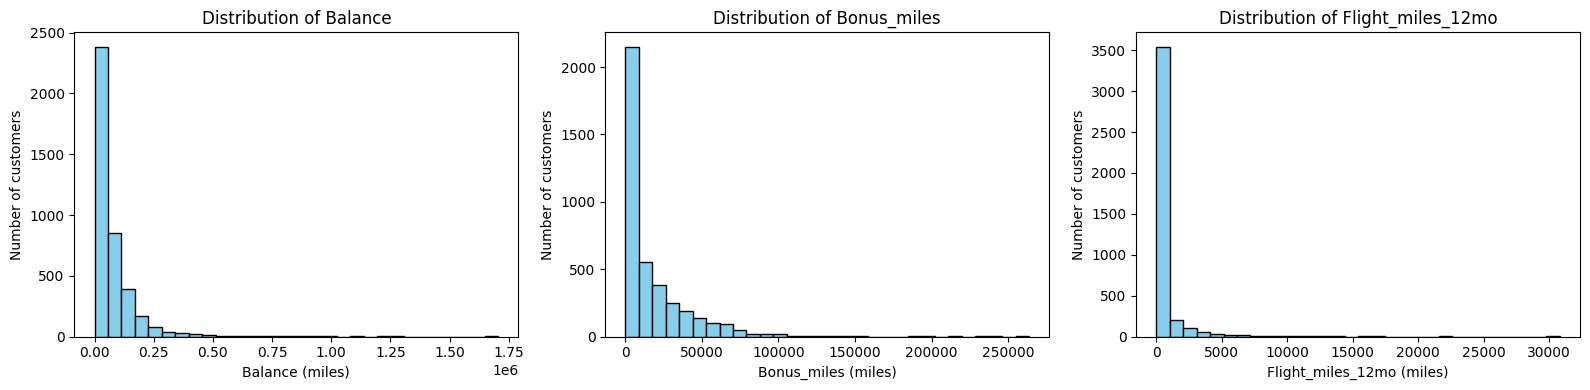

In [ ]:
import matplotlib.pyplot as plt

columns = ["Balance", "Bonus_miles", "Flight_miles_12mo"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, column in zip(axes, columns):
    ax.hist(X[column], bins=30, color="skyblue", edgecolor="black")
    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel(column + " (miles)")
    ax.set_ylabel("Number of customers")

plt.tight_layout()
plt.show()


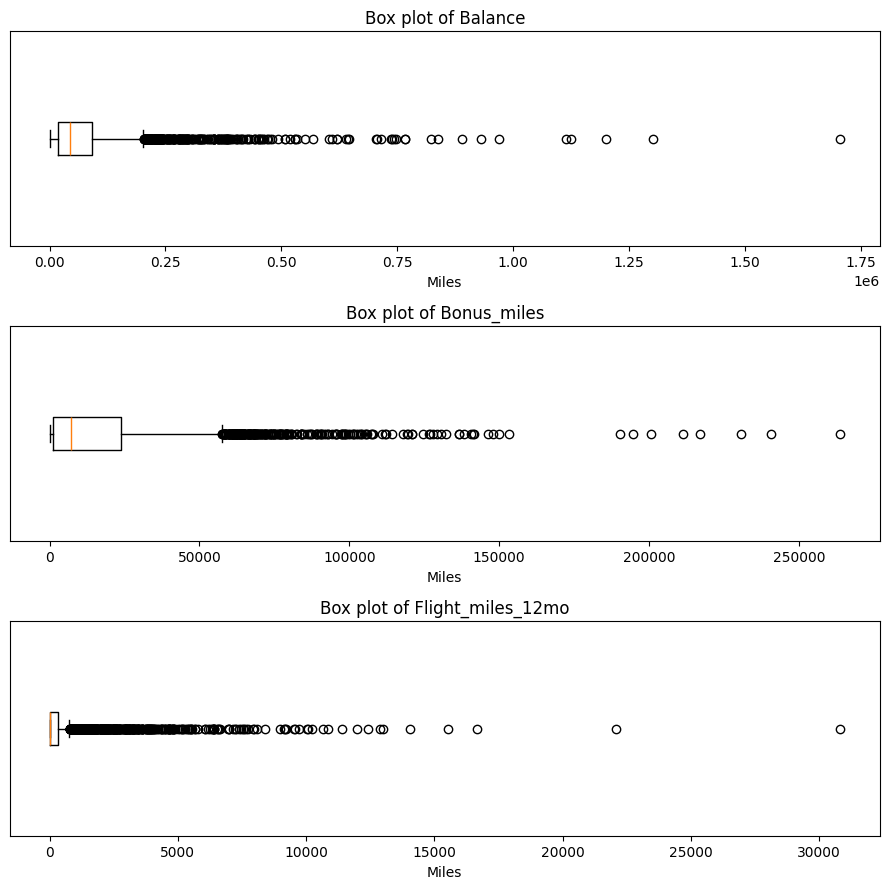

In [ ]:
columns = ["Balance", "Bonus_miles", "Flight_miles_12mo"]

fig, axes = plt.subplots(3, 1, figsize=(9, 9))

for ax, column in zip(axes, columns):
    ax.boxplot(X[column], vert=False)
    ax.set_title(f"Box plot of {column}")
    ax.set_xlabel("Miles")
    ax.set_yticks([])

plt.tight_layout()
plt.show()

In [ ]:
columns = ["Balance", "Bonus_miles", "Flight_miles_12mo"]

for column in columns:
    Q1 = X[column].quantile(0.25)
    Q3 = X[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = (X[column] < lower) | (X[column] > upper)

    print(column)
    print("Lower boundary:", round(lower, 2))
    print("Upper boundary:", round(upper, 2))
    print("Potential outliers:", outliers.sum())
    print("Percentage:", round(outliers.mean() * 100, 2), "%")
    print()


Balance
Lower boundary: -92287.25
Upper boundary: 203218.75
Potential outliers: 266
Percentage: 6.65 %

Bonus_miles
Lower boundary: -32575.75
Upper boundary: 57626.25
Potential outliers: 280
Percentage: 7.0 %

Flight_miles_12mo
Lower boundary: -466.5
Upper boundary: 777.5
Potential outliers: 569
Percentage: 14.23 %



In [ ]:
from sklearn.preprocessing import RobustScaler

scaler = RobustScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("Scaled dataset shape:", X_scaled.shape)
display(X_scaled.head())

Scaled dataset shape: (3999, 11)


,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,-0.202419,0.0,0.0,0.0,0.0,-0.310281,-0.785714,0.000000,0.0,0.839185,0.0
1,-0.322877,0.0,0.0,0.0,0.0,-0.308463,-0.714286,0.000000,0.0,0.829938,0.0
2,-0.023593,0.0,0.0,0.0,0.0,-0.135163,-0.571429,0.000000,0.0,0.849010,0.0
3,-0.383356,0.0,0.0,0.0,0.0,-0.295825,-0.785714,0.000000,0.0,0.825314,0.0
4,0.739816,0.0,1.5,0.0,0.0,1.602137,1.000000,6.678457,4.0,0.820402,1.0


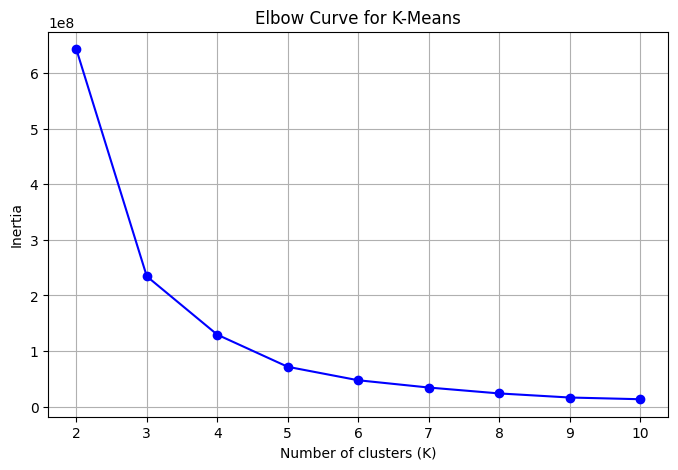

In [ ]:
from sklearn.cluster import KMeans

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o", color="blue")

plt.title("Elbow Curve for K-Means")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)

plt.show()

In [ ]:
import numpy as np
from sklearn.preprocessing import StandardScaler

X_processed = X.copy()

skewed_columns = [
    "Balance",
    "Qual_miles",
    "Bonus_miles",
    "Bonus_trans",
    "Flight_miles_12mo",
    "Flight_trans_12",
    "Days_since_enroll"
]

X_processed[skewed_columns] = np.log1p(X_processed[skewed_columns])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_processed)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

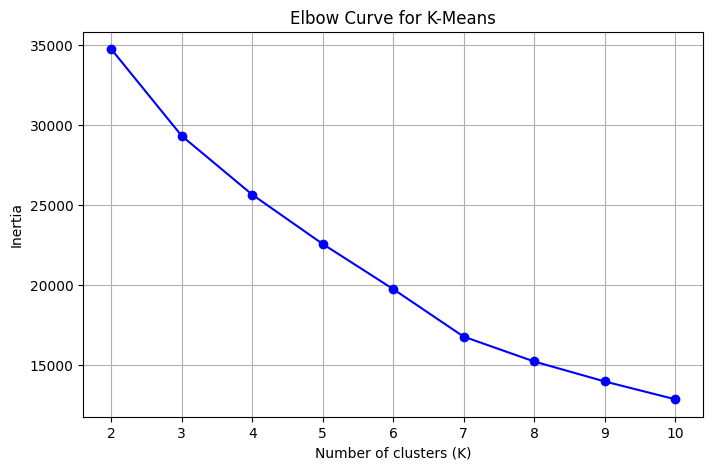

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia_values = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia_values, marker="o", color="blue")

plt.title("Elbow Curve for K-Means")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

silhouette_kmeans = silhouette_score(X_scaled, kmeans_labels)

print("K-Means Silhouette Score:", round(silhouette_kmeans, 4))

K-Means Silhouette Score: 0.2692


In [ ]:
df_kmeans = df.copy()

df_kmeans["Cluster"] = kmeans_labels

print("Number of customers in each cluster:")
print(df_kmeans["Cluster"].value_counts().sort_index())

Number of customers in each cluster:
Cluster
0    1048
1    1716
2     214
3    1006
4      15
Name: count, dtype: int64


In [ ]:
cluster_profile = df_kmeans.groupby("Cluster").mean().round(2)

important_columns = [
    "Balance",
    "Bonus_miles",
    "Flight_miles_12mo",
    "Flight_trans_12",
    "Days_since_enroll",
    "Award?"
]

display(cluster_profile[important_columns])

,Balance,Bonus_miles,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Cluster,,,,,,
0,108948.58,24996.10,1358.07,4.02,4473.27,0.57
1,73704.73,20236.73,0.09,0.00,4355.68,0.37
2,139046.61,25291.85,1805.76,5.44,4418.90,0.68
3,21719.08,813.84,22.18,0.09,3273.30,0.08
4,138061.40,93927.87,506.67,1.60,4613.87,0.53


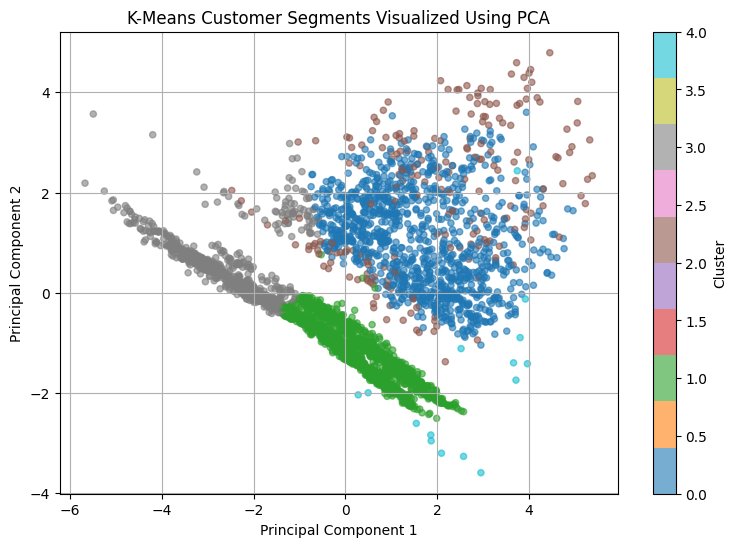

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="tab10",
    alpha=0.6,
    s=20
)

plt.title("K-Means Customer Segments Visualized Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

linkage_methods = ["ward", "complete", "average"]

for linkage_method in linkage_methods:
    hierarchical_model = AgglomerativeClustering(
        n_clusters=5,
        linkage=linkage_method
    )

    hierarchical_labels = hierarchical_model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, hierarchical_labels)

    print(
        f"Linkage: {linkage_method:<8} "
        f"Silhouette Score: {score:.4f}"
    )

Linkage: ward     Silhouette Score: 0.2634
Linkage: complete Silhouette Score: 0.2709
Linkage: average  Silhouette Score: 0.5582


In [ ]:
best_linkage = "ward"  # Change this if another method gets a higher score

hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage=best_linkage
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print(
    "Hierarchical Clustering Silhouette Score:",
    round(silhouette_score(X_scaled, hierarchical_labels), 4)
)

Hierarchical Clustering Silhouette Score: 0.2634


In [ ]:
best_linkage = "ward"

In [ ]:
best_linkage = "average"

hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage=best_linkage
)

hierarchical_labels = hierarchical.fit_predict(X_scaled)

print(
    "Hierarchical Clustering Silhouette Score:",
    round(silhouette_score(X_scaled, hierarchical_labels), 4)
)

Hierarchical Clustering Silhouette Score: 0.5582


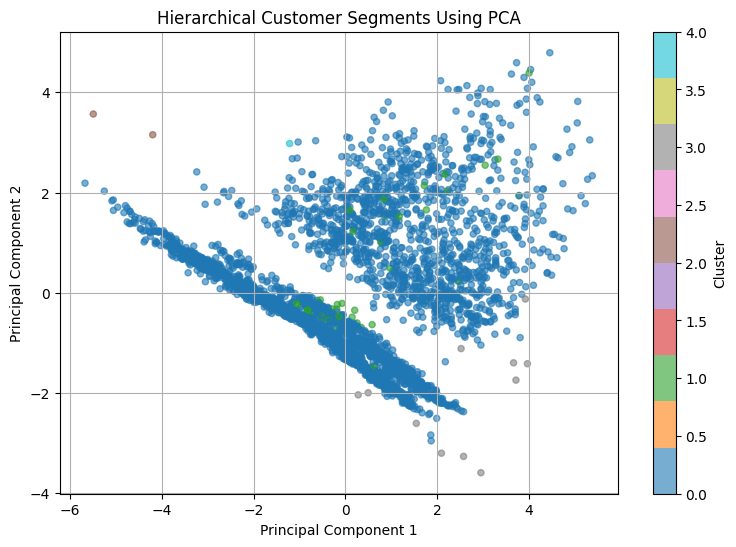

In [ ]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hierarchical_labels,
    cmap="tab10",
    alpha=0.6,
    s=20
)

plt.title("Hierarchical Customer Segments Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Cluster")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

eps_values = [0.8, 1.0, 1.2, 1.5, 2.0, 2.2, 2.5, 3.0]
dbscan_results = []

for eps in eps_values:
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(X_scaled)

    # -1 means noise
    number_of_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_points = (labels == -1).sum()

    # Calculate silhouette only for non-noise customers
    non_noise = labels != -1

    if number_of_clusters >= 2:
        score = silhouette_score(X_scaled[non_noise], labels[non_noise])
    else:
        score = None

    dbscan_results.append([eps, number_of_clusters, noise_points, score])

results_df = pd.DataFrame(
    dbscan_results,
    columns=["eps", "Clusters", "Noise points", "Silhouette score"]
)

display(results_df.round(4))

,eps,Clusters,Noise points,Silhouette score
0,0.8,10,813,0.2668
1,1.0,6,451,0.2643
2,1.2,10,269,0.2616
3,1.5,11,135,0.1757
4,2.0,6,59,0.2097
5,2.2,3,53,0.3899
6,2.5,4,30,0.3919
7,3.0,4,23,0.3918


In [ ]:
dbscan = DBSCAN(eps=2.5, min_samples=10)

dbscan_labels = dbscan.fit_predict(X_scaled)

non_noise = dbscan_labels != -1

dbscan_silhouette = silhouette_score(
    X_scaled[non_noise],
    dbscan_labels[non_noise]
)

number_of_clusters = len(set(dbscan_labels)) - 1
noise_points = (dbscan_labels == -1).sum()

print("Number of DBSCAN clusters:", number_of_clusters)
print("Noise points:", noise_points)
print("DBSCAN Silhouette Score:", round(dbscan_silhouette, 4))

Number of DBSCAN clusters: 4
Noise points: 30
DBSCAN Silhouette Score: 0.3919


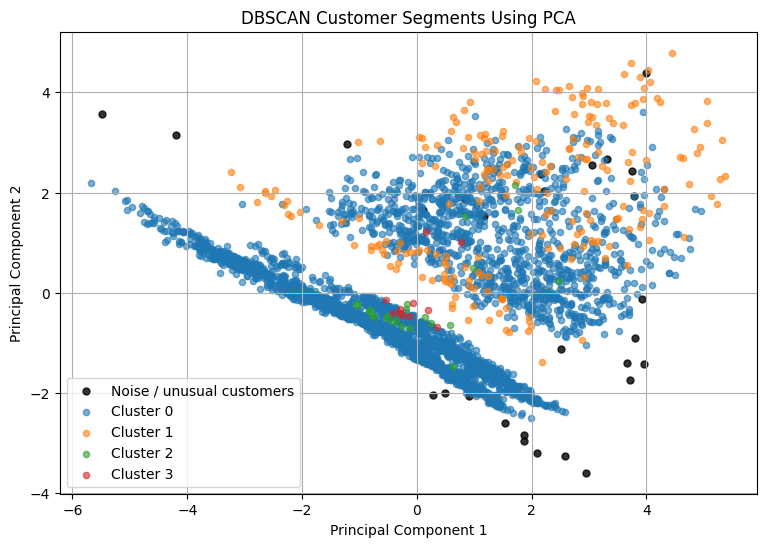

In [ ]:
plt.figure(figsize=(9, 6))

# Plot the four DBSCAN clusters
for cluster in sorted(set(dbscan_labels)):
    mask = dbscan_labels == cluster

    if cluster == -1:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            color="black",
            s=25,
            alpha=0.8,
            label="Noise / unusual customers"
        )
    else:
        plt.scatter(
            X_pca[mask, 0],
            X_pca[mask, 1],
            s=20,
            alpha=0.6,
            label=f"Cluster {cluster}"
        )

plt.title("DBSCAN Customer Segments Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(True)
plt.show()

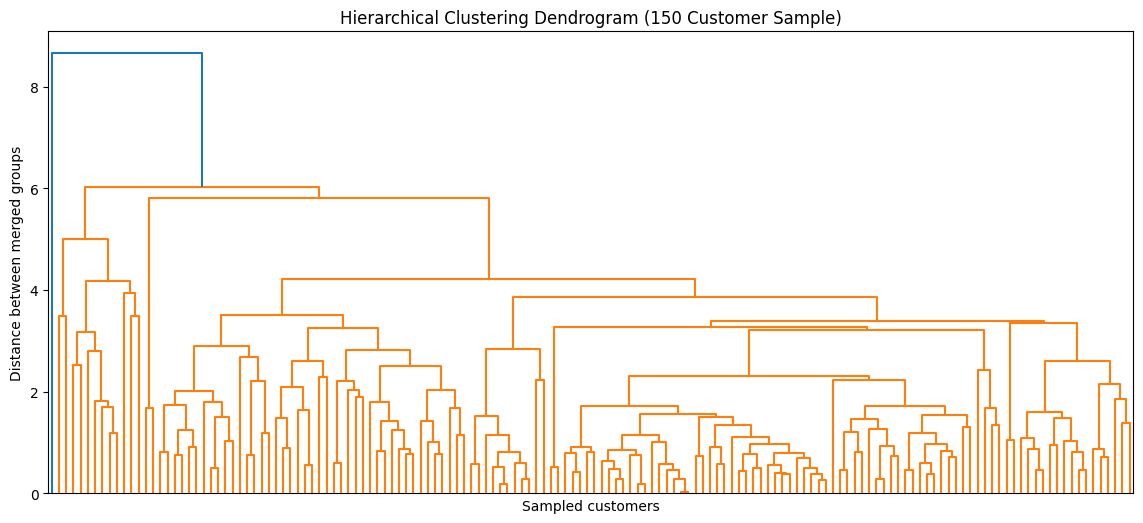

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Select the same random sample each time
sampled_data = X_scaled.sample(n=150, random_state=42)

# Build the hierarchy using the selected best method
Z = linkage(sampled_data, method="average")

plt.figure(figsize=(14, 6))

dendrogram(
    Z,
    no_labels=True,
    color_threshold=None
)

plt.title("Hierarchical Clustering Dendrogram (150 Customer Sample)")
plt.xlabel("Sampled customers")
plt.ylabel("Distance between merged groups")
plt.show()

In [ ]:
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means (K = 5)",
        "Hierarchical (Average Linkage, 5 clusters)",
        "DBSCAN (eps = 2.5, min_samples = 10)"
    ],
    "Clusters": [5, 5, 4],
    "Noise points": [0, 0, 30],
    "Silhouette score": [
        round(silhouette_kmeans, 4),
        round(silhouette_score(X_scaled, hierarchical_labels), 4),
        round(dbscan_silhouette, 4)
    ]
})

display(comparison)

,Algorithm,Clusters,Noise points,Silhouette score
0,K-Means (K = 5),5,0,0.2692
1,"Hierarchical (Average Linkage, 5 clusters)",5,0,0.5582
2,"DBSCAN (eps = 2.5, min_samples = 10)",4,30,0.3919


In [ ]:
profile_columns = [
    "Balance",
    "Qual_miles",
    "cc1_miles",
    "cc2_miles",
    "cc3_miles",
    "Bonus_miles",
    "Flight_miles_12mo",
    "Flight_trans_12",
    "Days_since_enroll",
    "Award?"
]

for name, labels in [
    ("Hierarchical", hierarchical_labels),
    ("DBSCAN", dbscan_labels)
]:
    result = df.copy()
    result["Cluster"] = labels

    counts = result.groupby("Cluster").size()

    summary = pd.DataFrame({
        "Customers": counts,
        "Percentage": (counts / len(result) * 100).round(2)
    })

    profile = result.groupby("Cluster")[profile_columns].mean().round(2)

    print(f"\n{name}: cluster sizes")
    print(summary.to_string())

    print(f"\n{name}: average customer characteristics")
    print(profile.to_string())


Hierarchical: cluster sizes
         Customers  Percentage
Cluster                       
0             3942       98.57
1               43        1.08
2                2        0.05
3               11        0.28
4                1        0.03

Hierarchical: average customer characteristics
           Balance  Qual_miles  cc1_miles  cc2_miles  cc3_miles  Bonus_miles  Flight_miles_12mo  Flight_trans_12  Days_since_enroll  Award?
Cluster                                                                                                                                    
0         73504.52      144.45       2.07       1.00       1.00     16949.41             458.73             1.36            4121.57    0.37
1         68876.58       23.26       1.14       2.35       1.00     14689.84             582.63             2.21            3968.93    0.40
2          3493.50     2950.50       1.00       1.00       1.00         0.00               0.00             0.00              16.00    0.00
3     

In [ ]:
dbscan_trials = []

for eps in [2.2, 2.5, 3.0]:
    for min_samples in [5, 10, 20]:
        trial = DBSCAN(eps=eps, min_samples=min_samples)
        labels = trial.fit_predict(X_scaled)

        non_noise = labels != -1
        cluster_count = len(set(labels[non_noise]))
        noise_count = int((~non_noise).sum())

        score = float("nan")

        if 2 <= cluster_count < non_noise.sum():
            score = silhouette_score(
                X_scaled[non_noise],
                labels[non_noise]
            )

        sizes = pd.Series(labels[non_noise]).value_counts()
        largest_pct = (
            100 * sizes.max() / len(labels)
            if not sizes.empty else 0
        )

        dbscan_trials.append([
            eps, min_samples, cluster_count,
            noise_count, largest_pct, score
        ])

dbscan_parameter_results = pd.DataFrame(
    dbscan_trials,
    columns=[
        "eps", "min_samples", "Clusters",
        "Noise", "Largest cluster %", "Silhouette"
    ]
)

print(dbscan_parameter_results.round(4).to_string(index=False))

 eps  min_samples  Clusters  Noise  Largest cluster %  Silhouette
 2.2            5         4     39            92.8232      0.3911
 2.2           10         3     53            92.8232      0.3899
 2.2           20         2     86            92.7732      0.3879
 2.5            5         4     27            92.8482      0.3919
 2.5           10         4     30            92.8482      0.3919
 2.5           20         2     70            92.8232      0.3894
 3.0            5         5     17            92.8482      0.3923
 3.0           10         4     23            92.8482      0.3918
 3.0           20         3     44            92.8482      0.3912
